## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

In [2]:
# Your Phase 1 solution to the problem goes here.
!git clone https://github.com/rushilnanga/A05-pca.git
%cd /content/A05-pca
!ls
!ls data

fatal: destination path 'A05-pca' already exists and is not an empty directory.
/content/A05-pca
data  notebook.ipynb  README.md
all_tokens.pickle  Phishing_clean.parquet


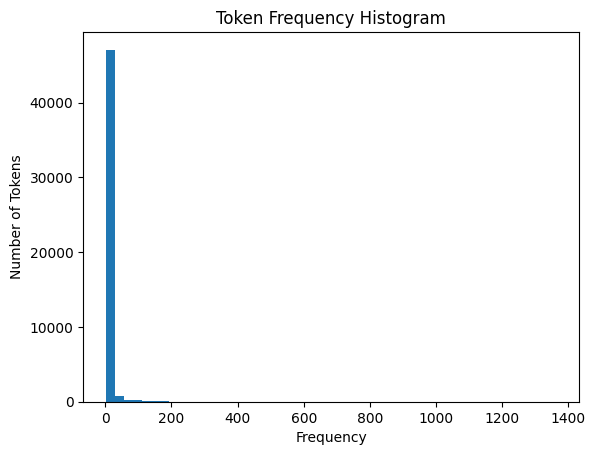

[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795)]


In [3]:
import pickle
import matplotlib.pyplot as plt
from collections import Counter

with open("data/all_tokens.pickle", "rb") as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()

frequencies = list(token_count.values())

plt.hist(frequencies, bins=50)
plt.xlabel("Frequency")
plt.ylabel("Number of Tokens")
plt.title("Token Frequency Histogram")
plt.show()

print(token_freq[:10])

# The histogram is very right skewed. Most of tokens occur only a few times while a small number of tokens occur very frequently. This creates a large concentration of tokens on the left side and a long tail to the right

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet("data/Phishing_clean.parquet")

print(df.shape)

X = df.drop(columns=["Email Type"])
y = df["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

print("Training R2:", model.score(X_train, y_train))
print("Test R2:", model.score(X_test, y_test))

coefficients = pd.Series(model.coef_, index=X.columns)

print(coefficients.reindex(
    coefficients.abs().sort_values(ascending=False).index
).head(10))

# The training R² was 0.7670 and the test R² was 0.6659 suggesting some overfitting. The words with the largest absolute coefficients were "intervention" (-1.259), "localized" (0.824), "thermal" (0.747), "crawler" (0.696), and "background-image:" (-0.623). These words have the strongest influence on the model's predictions

(18634, 2712)
Training R2: 0.7670143724934355
Test R2: 0.6658718438847919
intervention        -1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:   -0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;               -0.574480
a:active             0.574480
dtype: float64


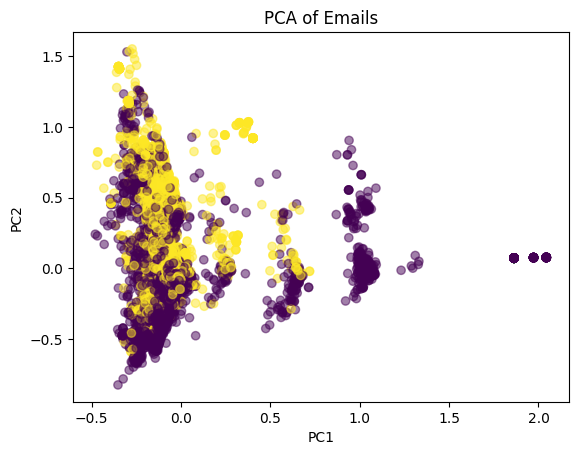

In [5]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    alpha=0.5
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Emails")
plt.show()

# Although the PCA scatterplot shows some differences between scam and non scam emails, there is a lot of overlap between the two. Most emails are concentrated on the left side of the plot while some groups appear a bit farther to the right. The two types of emails are not clearly separated indicating that the first two principal components alone are not enough to distinguish scams from non scams.

In [6]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression

pca_large = PCA(
    n_components=2610,
    svd_solver="randomized",
    random_state=42
)

X_train_pca = pca_large.fit_transform(X_train)
X_test_pca = pca_large.transform(X_test)

model_pca = LinearRegression()
model_pca.fit(X_train_pca, y_train)

print("Original regression:")
print("Training R2:", model.score(X_train, y_train))
print("Test R2:", model.score(X_test, y_test))

print("\nPCA regression:")
print("Training R2:", model_pca.score(X_train_pca, y_train))
print("Test R2:", model_pca.score(X_test_pca, y_test))

# The linear regression had a training R² of 0.7670 and a test R² of 0.6659 while the PCA regression had a training R² of 0.7662 and a test R² of 0.6684. The PCA model performed slightly better on the test set while its training R² was slightly lower. Overall, both models performed at an equal level suggesting that PCA could accurately get most of the predictive performance while reducing the number of features from 2711 to 2610

Original regression:
Training R2: 0.7670143724934355
Test R2: 0.6658718438847919

PCA regression:
Training R2: 0.7661790402020929
Test R2: 0.668449827853717


5) The main advantage of using PCA in this context is the fact that it reduces the number of variables by combining the original features into principal components. This can make regression easier when there are thousands of variables and can reduce problems caused by correlated features. It may also help reduce overfitting when compared to using the original data

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [7]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]